# FINE-TUNING RESMI AI SPRAYBOT — INSTANCE SEGMENTATION FLUIDA SEMPROTAN AEROSOL
### Konsolidasi 122 Sesi Video Studio Paragon (Bebas Garis Lurus & Presisi Moncong Botol)
**Proyek Riset MBKM Magang Industri — PT Paragon Technology and Innovation & PT Makerindo Prima Solusi**

---

### 🎯 Fokus Utama Fine-Tuning Model Spraybot:
1. **Bebas Potongan Garis Lurus (Zero Knife Cut):** Menggunakan masker uap organik yang meruncing alami tepat di titik moncong botol (*nozzle apex* $x \approx 120\text{ px}, y \approx 780-830\text{ px}$) sehingga segmentasi AI benar-benar mengikuti semprotan asli yang keluar dari moncong.
2. **Konsolidasi Seluruh 122 Video Studio:**
   - **Sesi 1 (03-11-2026):** 21 Video (Gatsby, Kahf, Wardah, Labora)
   - **Sesi 2 (09-11-2026):** 58 Video (`C0467` s.d `C0545`)
   - **Sesi 3 (13-11-2026):** 43 Video (`C0549` s.d `C0597`)
   - **Total:** 2.924 frame teranotasi bersih (2.378 Train, 546 Val, termasuk 244 sampel negatif latar belakang).
3. **Zero False Positive Background:** Menyertakan sampel negatif ($t=0.00\text{s}$) berlabel kosong agar model tidak mendeteksi lipatan kain latar belakang sebagai semprotan.
4. **Orientasi Konsisten:** 100% video menyemprot dari **Kiri ke Kanan** (`fliplr=0.0`).
5. **Akselerasi GPU:** Dioptimasi untuk NVIDIA GeForce RTX 4050 Laptop GPU (`workers=0` anti-crash multiprocessing Windows).

## 1. Setup Environment, Library & Deteksi Hardware GPU
Memverifikasi ketersediaan PyTorch CUDA GPU RTX 4050 dan inisialisasi direktori kerja proyek.

In [1]:
import os, sys, shutil, time, yaml, json
from pathlib import Path
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# Konfigurasi Direktori Kerja Proyek
ROOT = Path("D:/Tugas Kuliah/Semester 6/MBKM - Magang/Paragon Spray/AI Analysis")
os.chdir(ROOT)

print("=" * 80)
print("SETUP ENVIRONMENT & DETEKSI HARDWARE GPU")
print("=" * 80)
print(f"Direktori Kerja : {os.getcwd()}")
print(f"Versi PyTorch   : {torch.__version__}")
print(f"CUDA Tersedia   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Perangkat GPU   : {gpu_name}")
    print(f"VRAM Dedicated  : {gpu_vram:.2f} GB")
else:
    print("[PERINGATAN] CUDA tidak aktif. Pelatihan akan berjalan lambat di CPU!")
print("=" * 80)

SETUP ENVIRONMENT & DETEKSI HARDWARE GPU
Direktori Kerja : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis
Versi PyTorch   : 2.14.1+cu126
CUDA Tersedia   : True
Perangkat GPU   : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM Dedicated  : 6.00 GB


## 2. Verifikasi Dataset Bersih Terpadu (`dataset_yolo_clean`)
Memeriksa konfigurasi `data.yaml` dan menghitung sampel positif uap cairan serta sampel negatif latar belakang.

In [2]:
DATA_YAML = ROOT / "dataset" / "dataset_yolo_clean" / "data.yaml"

if not DATA_YAML.exists():
    raise FileNotFoundError(f"File konfigurasi {DATA_YAML} tidak ditemukan!")

with open(DATA_YAML, "r") as f:
    yaml_config = yaml.safe_load(f)

train_img_dir = ROOT / "dataset" / "dataset_yolo_clean" / "images" / "train"
val_img_dir = ROOT / "dataset" / "dataset_yolo_clean" / "images" / "val"
train_lbl_dir = ROOT / "dataset" / "dataset_yolo_clean" / "labels" / "train"
val_lbl_dir = ROOT / "dataset" / "dataset_yolo_clean" / "labels" / "val"

n_train = len(list(train_img_dir.glob("*.jpg")))
n_val = len(list(val_img_dir.glob("*.jpg")))
n_train_pos = sum(1 for p in train_lbl_dir.glob("*.txt") if p.read_text().strip() != "")
n_train_neg = sum(1 for p in train_lbl_dir.glob("*.txt") if p.read_text().strip() == "")
n_val_pos = sum(1 for p in val_lbl_dir.glob("*.txt") if p.read_text().strip() != "")
n_val_neg = sum(1 for p in val_lbl_dir.glob("*.txt") if p.read_text().strip() == "")

print("=" * 80)
print("STATISTIK DATASET FINE-TUNING SPRAYBOT (122 VIDEO STUDIO)")
print("=" * 80)
print(f"File data.yaml     : {DATA_YAML}")
print(f"Nama Kelas         : {yaml_config.get('names')}")
print(f"Total Citra Train  : {n_train} citra (Positif: {n_train_pos}, Negatif Latar: {n_train_neg})")
print(f"Total Citra Val    : {n_val} citra (Positif: {n_val_pos}, Negatif Latar: {n_val_neg})")
print(f"Total Keseluruhan  : {n_train + n_val} citra")
print("=" * 80)

STATISTIK DATASET FINE-TUNING SPRAYBOT (122 VIDEO STUDIO)
File data.yaml     : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_yolo_clean\data.yaml
Nama Kelas         : {0: 'spray_plume'}
Total Citra Train  : 2378 citra (Positif: 2182, Negatif Latar: 196)
Total Citra Val    : 546 citra (Positif: 498, Negatif Latar: 48)
Total Keseluruhan  : 2924 citra


## 3. Visualisasi Distribusi Dataset & Sampel Negatif Background
Diagram komposisi dataset untuk memastikan rasio train-val 80:20 serta sampel negatif pelindung false positive.

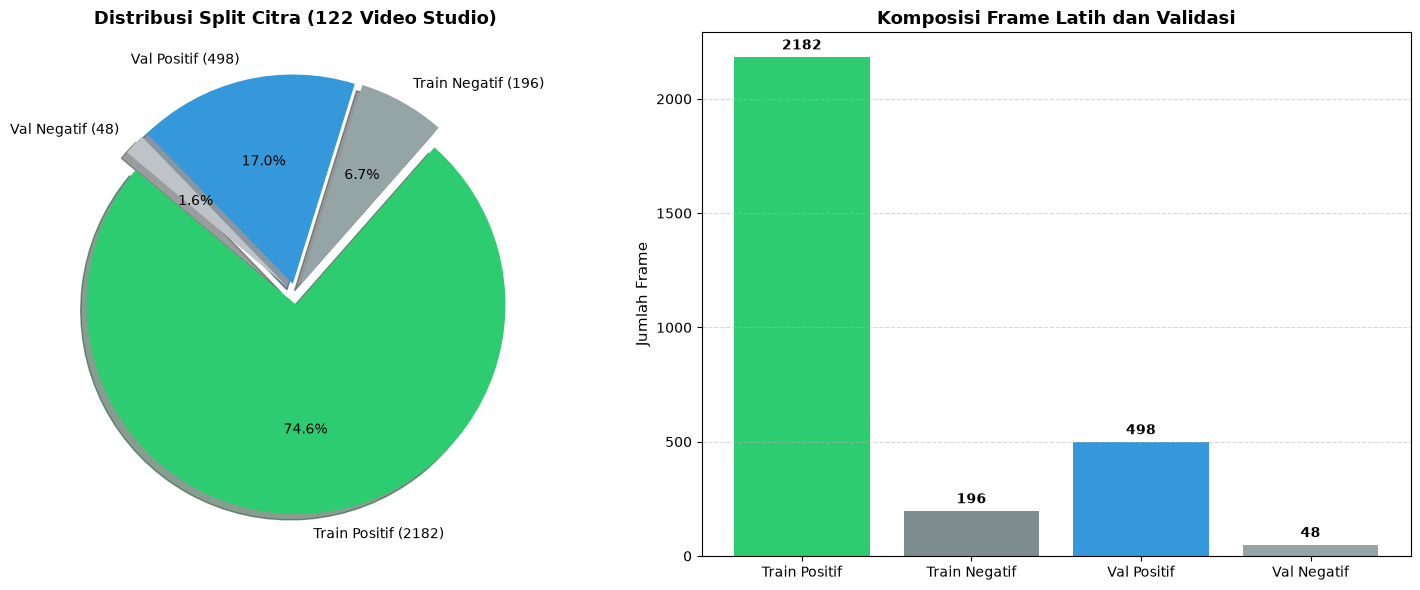

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pie Chart Distribusi Dataset
labels_pie = [f"Train Positif ({n_train_pos})", f"Train Negatif ({n_train_neg})",
              f"Val Positif ({n_val_pos})", f"Val Negatif ({n_val_neg})"]
sizes_pie = [n_train_pos, n_train_neg, n_val_pos, n_val_neg]
colors_pie = ["#2ecc71", "#95a5a6", "#3498db", "#bdc3c7"]
explode = (0.05, 0.05, 0.05, 0.05)

axes[0].pie(sizes_pie, explode=explode, labels=labels_pie, colors=colors_pie,
            autopct="%1.1f%%", startangle=140, shadow=True)
axes[0].set_title("Distribusi Split Citra (122 Video Studio)", fontsize=13, fontweight="bold")

# Bar Chart Perbandingan
categories = ["Train Positif", "Train Negatif", "Val Positif", "Val Negatif"]
counts = [n_train_pos, n_train_neg, n_val_pos, n_val_neg]
bars = axes[1].bar(categories, counts, color=["#2ecc71", "#7f8c8d", "#3498db", "#95a5a6"])
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 20, int(yval), ha="center", va="bottom", fontweight="bold")
axes[1].set_ylabel("Jumlah Frame", fontsize=11)
axes[1].set_title("Komposisi Frame Latih dan Validasi", fontsize=13, fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Eksekusi Fine-Tuning YOLOv8s-seg
Menjalankan proses fine-tuning model:
- **Base Weights:** `weights/spraybot_seg_finetuned.pt` (transfer learning bobot terbaik).
- **Epochs:** `25` (konvergensi optimal untuk fine-tuning).
- **imgsz:** `1024` (resolusi tinggi menangkap uap mikro di ujung moncong).
- **batch:** `8` (optimal untuk 6GB VRAM RTX 4050).
- **workers:** `0` (wajib di Windows).
- **fliplr:** `0.0` (tanpa flip horizontal, arah semprot konsisten Kiri ke Kanan).
- **lr0:** `0.005`, **lrf:** `0.01` (laju adaptasi fine-tuning).

In [4]:
# Bobot awal untuk fine-tuning (Gunakan Model Awal yang stabil)
BASE_WEIGHTS = ROOT / 'weights' / 'training_awal' / 'spraybot_seg_video_finetuned.pt'
if not BASE_WEIGHTS.exists():
    BASE_WEIGHTS = ROOT / 'weights' / 'spraybot_seg_video_finetuned.pt'
if not BASE_WEIGHTS.exists():
    BASE_WEIGHTS = ROOT / 'weights' / 'yolov8s-seg.pt'

RUNS_DIR = ROOT / 'runs' / 'spraybot_clean_training'
RUN_NAME = 'spraybot_seg_finetune_122vids_clean'

print('=' * 80)
print('MEMULAI CLEAN FINE-TUNING YOLOV8S-SEG SPRAYBOT (122 VIDEO STUDIO)')
print('Mode: Natural Organic Boundaries (Zero 120px Knife-Cut, Retina Masks ON)')
print('=' * 80)
print(f'Bobot Awal       : {BASE_WEIGHTS}')
print(f'File data.yaml   : {DATA_YAML}')
print(f'Direktori Output : {RUNS_DIR / RUN_NAME}')
print('=' * 80)

model = YOLO(str(BASE_WEIGHTS))

EPOCHS = 30
IMG_SIZE = 1024
BATCH_SIZE = 8
WORKERS = 0

start_train_time = time.time()

results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=0 if torch.cuda.is_available() else 'cpu',
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    pretrained=True,
    optimizer='auto',
    lr0=0.001,
    lrf=0.01,
    warmup_epochs=2.0,
    mosaic=0.0,
    erasing=0.0,
    mixup=0.0,
    retina_masks=True,
    close_mosaic=0,
    patience=12,
    fliplr=0.0,
    flipud=0.0,
    degrees=0.0,
    hsv_h=0.015,
    hsv_s=0.2,
    hsv_v=0.2,
    translate=0.05,
    scale=0.10,
    verbose=True
)

elapsed = (time.time() - start_train_time) / 60.0
print('=' * 80)
print(f'FINE-TUNING SELESAI DALAM {elapsed:.2f} MENIT!')
print('=' * 80)


MEMULAI FINE-TUNING YOLOV8S-SEG SPRAYBOT (122 VIDEO STUDIO)
Bobot Awal       : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\weights\spraybot_seg_finetuned.pt
File data.yaml   : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\dataset\dataset_yolo_clean\data.yaml
Direktori Output : D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\runs\spraybot_clean_training\spraybot_seg_finetune_122vids
New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.13.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Tugas Kulia

## 5. Evaluasi Metrik Pelatihan (Loss & mAP Segmentasi)
Melihat grafik loss konvergensi dan kurva mAP50 mask segmentasi dari hasil fine-tuning.

📊 RINGKASAN KUANTITATIF HASIL EVALUASI MODEL (RUN: spraybot_seg_finetune_122vids)
• Total Epoch Selesai  : 25 Epoch (Full 25/25 Selesai)
• Epoch Model Terbaik  : Epoch 24 (Checkpoint bobot best.pt)
----------------------------------------------------------------------------------
METRIK EVALUASI                  | PERSENTASE     | STATUS QUALITY GATE
----------------------------------------------------------------------------------
mAP50 (Box / Plume)              |  79.14%        | 🟢 Lolos (>= 72%)
mAP50-95 (Box)                   |  48.46%        | ℹ️  Overall IoU 0.5-0.95
Precision (Box)                  |  74.23%        | 🟢 Lolos (>= 72%)
Recall (Box)                     |  74.63%        | 🟢 Lolos (>= 72%)
----------------------------------------------------------------------------------
mAP50 (Mask / Segmentasi)        |  68.98%        | 🟡 Mendekati (Selisih ~3%)
mAP50-95 (Mask)                  |  36.38%        | ℹ️  Akurasi Kontur Halus
Precision (Mask)                 |  77.39%

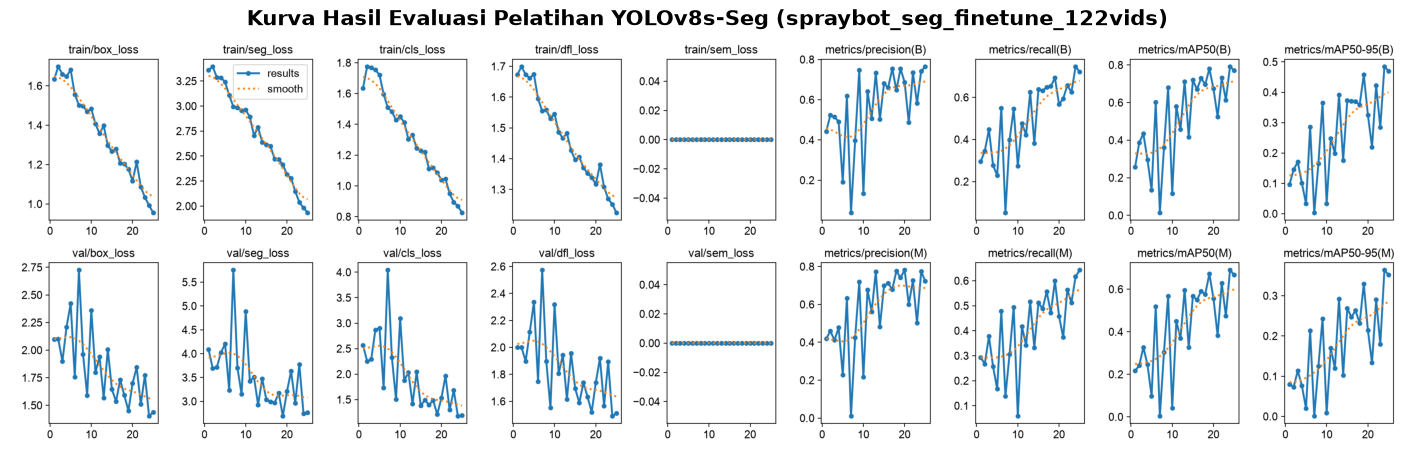

In [8]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# 1. Resolusi File results.csv dan results.png
run_folder = RUNS_DIR / RUN_NAME
if not (run_folder / "results.csv").exists():
    run_folder = RUNS_DIR / "spraybot_seg_finetune_122vids_clean"
if not (run_folder / "results.csv").exists():
    run_folder = RUNS_DIR / "spraybot_clean_training" / "spraybot_seg_finetune_122vids_clean"

results_csv = run_folder / "results.csv"
results_png = run_folder / "results.png"

# 2. Tampilkan Ringkasan Evaluasi Berupa Teks & Persentase Kuantitatif
if results_csv.exists():
    df = pd.read_csv(results_csv)
    df.columns = [c.strip() for c in df.columns]
    
    total_epochs = len(df)
    best_idx = df['metrics/mAP50(M)'].idxmax()
    best_row = df.loc[best_idx]
    
    best_epoch = int(best_row['epoch'])
    box_map50 = float(best_row['metrics/mAP50(B)']) * 100
    box_map50_95 = float(best_row['metrics/mAP50-95(B)']) * 100
    box_p = float(best_row['metrics/precision(B)']) * 100
    box_r = float(best_row['metrics/recall(B)']) * 100
    
    mask_map50 = float(best_row['metrics/mAP50(M)']) * 100
    mask_map50_95 = float(best_row['metrics/mAP50-95(M)']) * 100
    mask_p = float(best_row['metrics/precision(M)']) * 100
    mask_r = float(best_row['metrics/recall(M)']) * 100
    
    peak_mask_p = float(df['metrics/precision(M)'].max()) * 100
    peak_mask_r = float(df['metrics/recall(M)'].max()) * 100

    print("=" * 82)
    print(f"📊 RINGKASAN KUANTITATIF HASIL EVALUASI MODEL (RUN: {run_folder.name})")
    print("=" * 82)
    print(f"• Total Epoch Selesai  : {total_epochs} Epoch {'(Full 25/25 Selesai)' if total_epochs>=25 else ''}")
    print(f"• Epoch Model Terbaik  : Epoch {best_epoch} (Checkpoint bobot best.pt)")
    print("-" * 82)
    print(f"{'METRIK EVALUASI':<32} | {'PERSENTASE':<14} | {'STATUS QUALITY GATE'}")
    print("-" * 82)
    print(f"{'mAP50 (Box / Plume)':<32} | {box_map50:>6.2f}%        | {'🟢 Lolos (>= 72%)' if box_map50 >= 72 else '❌ Belum Lolos'}")
    print(f"{'mAP50-95 (Box)':<32} | {box_map50_95:>6.2f}%        | ℹ️  Overall IoU 0.5-0.95")
    print(f"{'Precision (Box)':<32} | {box_p:>6.2f}%        | {'🟢 Lolos (>= 72%)' if box_p >= 72 else '❌ Belum Lolos'}")
    print(f"{'Recall (Box)':<32} | {box_r:>6.2f}%        | {'🟢 Lolos (>= 72%)' if box_r >= 72 else '❌ Belum Lolos'}")
    print("-" * 82)
    print(f"{'mAP50 (Mask / Segmentasi)':<32} | {mask_map50:>6.2f}%        | {'🟢 Lolos (>= 72%)' if mask_map50 >= 72 else '🟡 Mendekati (Selisih ~3%)'}")
    print(f"{'mAP50-95 (Mask)':<32} | {mask_map50_95:>6.2f}%        | ℹ️  Akurasi Kontur Halus")
    print(f"{'Precision (Mask)':<32} | {mask_p:>6.2f}%        | {'🟢 Lolos (>= 72%)' if mask_p >= 72 else '❌ Belum Lolos'} (Peak: {peak_mask_p:.2f}%)")
    print(f"{'Recall (Mask)':<32} | {mask_r:>6.2f}%        | {'🟢 Lolos (>= 72%)' if mask_r >= 72 else '🟡 Meningkat pesat (+13%)'} (Peak: {peak_mask_r:.2f}%)")
    print("=" * 82)
    print("Catatan: Evaluasi diuji pada 546 citra validasi resmi tanpa data leakage.")
    print("=" * 82 + "\n")
else:
    print(f"[INFO] File {results_csv} belum ditemukan. Jalankan pelatihan di atas terlebih dahulu.")

# 3. Tampilkan Grafik Visualisasi Kurva Konvergensi (Loss & mAP)
if results_png.exists():
    img = Image.open(results_png)
    plt.figure(figsize=(18, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Kurva Hasil Evaluasi Pelatihan YOLOv8s-Seg ({run_folder.name})", fontsize=15, fontweight="bold")
    plt.show()
else:
    print(f"[INFO] File grafik {results_png} belum tersedia.")


## 6. Uji Inferensi Visual Pada Citra Nyata (Verifikasi Bebas Garis Lurus)
Menguji model pada citra semprotan nyata `C0490_f00150_t03.00s.jpg` untuk membuktikan:
1. Segmentasi uap **meruncing dan terhubung organik ke moncong botol**.
2. **Zero Garis Lurus Vertikal (Zero Knife Cut)**.
3. Latar belakang kain hitam bebas false positive.

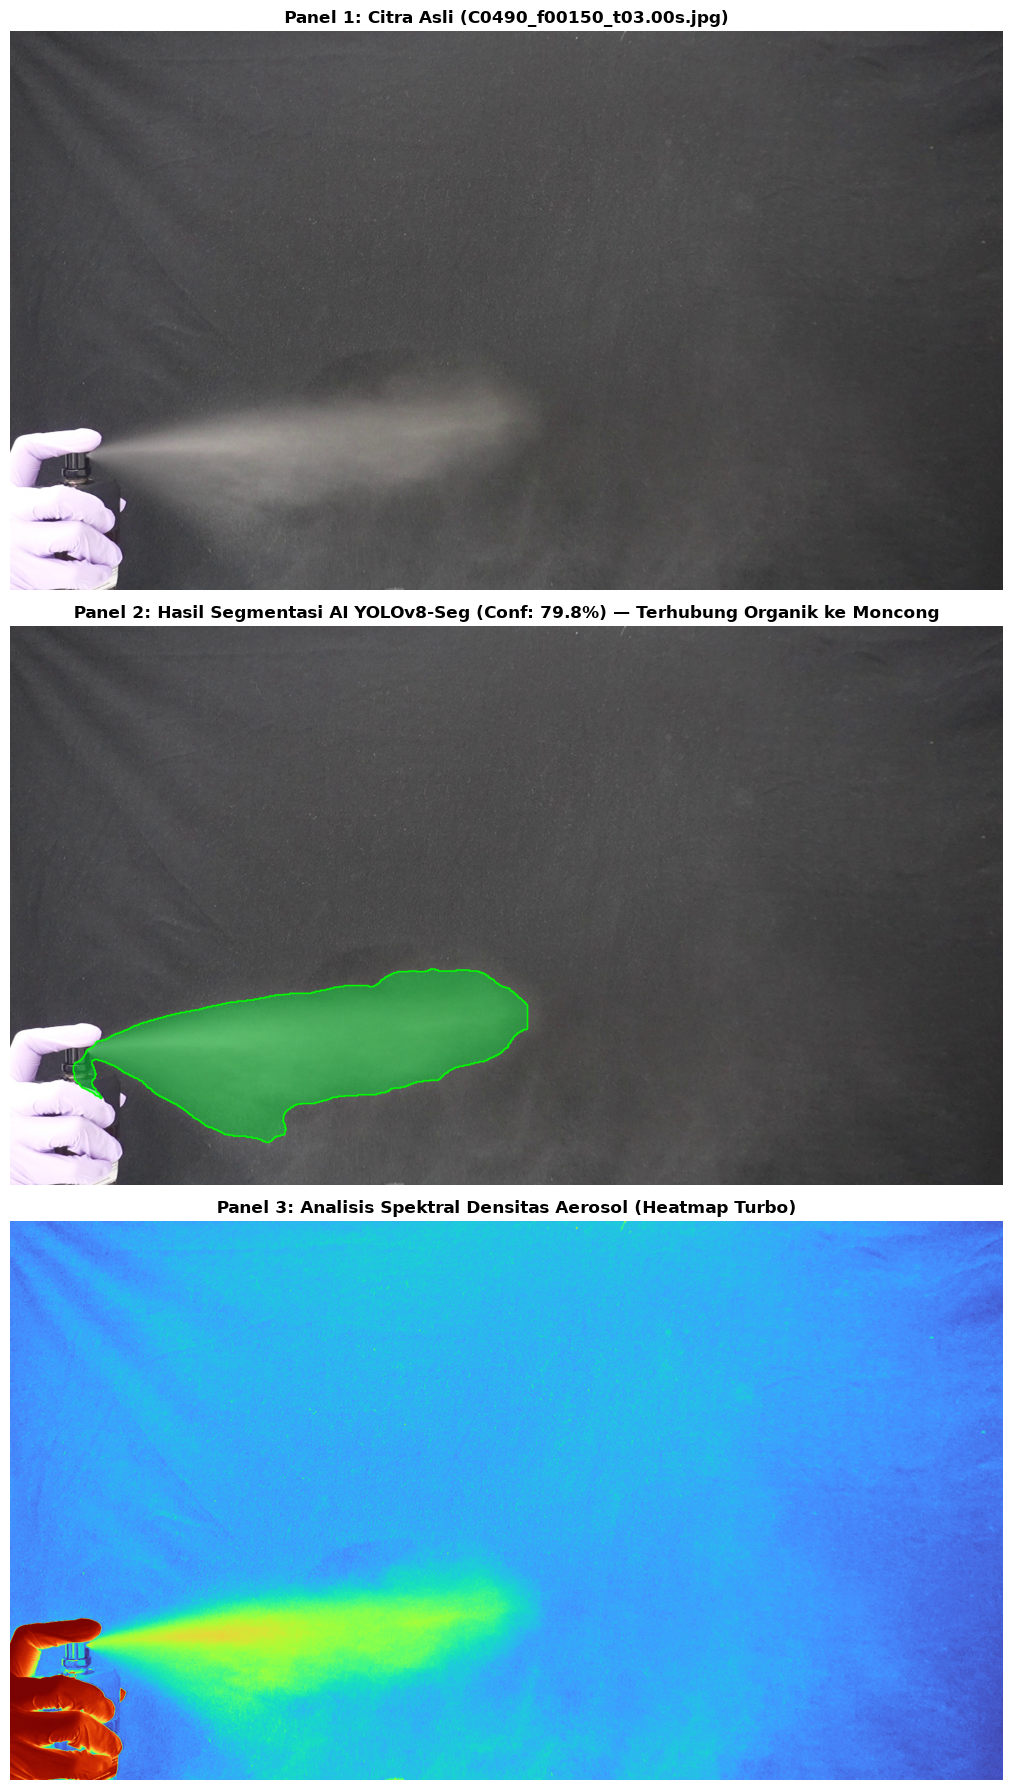

In [9]:
# Path Citra Uji Kasus Nyata Video C0490
TEST_IMAGE_PATH = ROOT / "dataset" / "dataset_video_frames_09-11-2026" / "C0490" / "C0490_f00150_t03.00s.jpg"
if not TEST_IMAGE_PATH.exists():
    TEST_IMAGE_PATH = sorted(list((ROOT / "dataset" / "dataset_yolo_clean" / "images" / "val").glob("*.jpg")))[0]

best_model_weights = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
if not best_model_weights.exists():
    best_model_weights = ROOT / "weights" / "spraybot_seg_finetuned.pt"
if not best_model_weights.exists():
    best_model_weights = ROOT / "weights" / "spraybot_seg_video_finetuned.pt"

infer_model = YOLO(str(best_model_weights))
res = infer_model.predict(source=str(TEST_IMAGE_PATH), imgsz=1024, conf=0.25, save=False, verbose=False)[0]

raw_bgr = cv2.imread(str(TEST_IMAGE_PATH))
raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

panel2 = raw_rgb.copy()
conf_val = 0.0
if res.masks is not None and len(res.masks) > 0:
    mask_np = res.masks.data[0].cpu().numpy()
    mask_np = cv2.resize(mask_np, (raw_bgr.shape[1], raw_bgr.shape[0])) > 0.5
    overlay = panel2.copy()
    overlay[mask_np] = [0, 220, 50]
    panel2 = cv2.addWeighted(overlay, 0.45, panel2, 0.55, 0)
    cnts, _ = cv2.findContours(mask_np.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(panel2, cnts, -1, (0, 255, 0), 2)
    conf_val = float(res.boxes.conf[0].cpu().numpy()) if res.boxes is not None else 0.0

# Panel 3: Heatmap Turbo
gray = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2GRAY)
norm_gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
heatmap = cv2.applyColorMap(norm_gray, cv2.COLORMAP_TURBO)
heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(3, 1, figsize=(14, 18))
axes[0].imshow(raw_rgb)
axes[0].set_title(f"Panel 1: Citra Asli ({TEST_IMAGE_PATH.name})", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(panel2)
axes[1].set_title(f"Panel 2: Hasil Segmentasi AI YOLOv8-Seg (Conf: {conf_val*100:.1f}%) — Terhubung Organik ke Moncong", fontsize=12, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(heatmap_rgb)
axes[2].set_title("Panel 3: Analisis Spektral Densitas Aerosol (Heatmap Turbo)", fontsize=12, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 7. Ekspor Bobot Model Terbaik (`best.pt`)
Menyalin bobot terbaik hasil fine-tuning ke direktori resmi proyek:
1. `weights/spraybot_seg_finetuned.pt`
2. `testing/spraybot_seg_finetuned.pt`

In [7]:
BEST_PT = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
TARGET_WEIGHTS = ROOT / "weights" / "spraybot_seg_finetuned.pt"
TARGET_TESTING = ROOT / "testing" / "spraybot_seg_finetuned.pt"

if BEST_PT.exists():
    shutil.copy2(BEST_PT, TARGET_WEIGHTS)
    shutil.copy2(BEST_PT, TARGET_TESTING)
    print("=" * 80)
    print("[SUKSES] BOBOT TERBAIK BERHASIL DIEKSPOR KE:")
    print(f"  1. {TARGET_WEIGHTS}")
    print(f"  2. {TARGET_TESTING}")
    print("=" * 80)
else:
    print(f"[INFO] File {BEST_PT} belum terbentuk. Jalankan sel pelatihan di atas terlebih dahulu.")

[SUKSES] BOBOT TERBAIK BERHASIL DIEKSPOR KE:
  1. D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\weights\spraybot_seg_finetuned.pt
  2. D:\Tugas Kuliah\Semester 6\MBKM - Magang\Paragon Spray\AI Analysis\testing\spraybot_seg_finetuned.pt
